In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["NUMBA_NUM_THREADS"] = "2"

import sys
import json
import platform
from pathlib import Path
from datetime import datetime
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits
from umap import UMAP

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160, "font.size": 10})
SEED = 42
STUDENT = "38720260158060-李嘉源"
INITIAL_JUDGMENT = "证据不足，暂不接受该主张（运行前分析预期）"
INITIAL_CONFIDENCE = 45

# 从仓库根目录或提交目录运行，均可定位同一份课程输入。
ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "assignments/hw04/resources/data/leukemia/leukemia.csv").is_file()
)
DATA_PATH = ROOT / "assignments/hw04/resources/data/leukemia/leukemia.csv"
SUBMISSION_DIR = ROOT / "submissions/hw04" / STUDENT
RUN_DIR = (
    ROOT / ".tmp/dimension-reduction/student-results" / STUDENT
    / datetime.now().strftime("run-%Y%m%d-%H%M%S-%f")
)
RUN_DIR.mkdir(parents=True)
packages = ["numpy", "pandas", "scipy", "scikit-learn", "umap-learn",
            "matplotlib", "threadpoolctl", "nbformat", "ipykernel"]
versions = {"Python": platform.python_version(), **{p: version(p) for p in packages}}
display(pd.Series(versions, name="actual_version").to_frame())
print("Python executable:", sys.executable)
print("Execution host:", platform.node())
print("Input:", DATA_PATH.relative_to(ROOT))
print("Generated results:", RUN_DIR.relative_to(ROOT))
(RUN_DIR / "versions.json").write_text(
    json.dumps(versions, ensure_ascii=False, indent=2), encoding="utf-8"
)

def markdown_table(table, digits=6):
    # 避免为 Markdown 表格额外安装 tabulate。
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}"
        return str(value).replace("|", "/").replace("\n", " ")
    lines = [
        "| " + " | ".join(map(str, table.columns)) + " |",
        "| " + " | ".join(["---"] * len(table.columns)) + " |",
    ]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |"
              for row in table.itertuples(index=False, name=None)]
    return "\n".join(lines)

,actual_version
Python,3.12.13
numpy,1.26.4
pandas,2.1.1
scipy,1.17.1
scikit-learn,1.8.0
umap-learn,0.5.11
matplotlib,3.10.8
threadpoolctl,3.6.0
nbformat,5.10.4
ipykernel,7.2.0


Python executable: /cluster/huanglab/jiayuan/miniconda/envs/snapatac2/bin/python
Execution host: node4
Input: assignments/hw04/resources/data/leukemia/leukemia.csv
Generated results: .tmp/dimension-reduction/student-results/38720260158060-李嘉源/run-20261105-103425-631963


## 数据准备：一行是什么，哪些列进入分析？
一行是一份白血病样本的微阵列表达谱，sample_id 是教学编号。
模型输入仅为 7,129 个探针列；sample_id、original_split、diagnosis 均排除。
先核对形状、有限数值、常量列与类别分布，以发现错读数据或元数据混入特征。
本数据含负值，保留其数值，不做 RNA-seq 计数归一化、不取 log/log1p、不按诊断筛选探针。

In [3]:
df = pd.read_csv(DATA_PATH)
meta_columns = ["sample_id", "original_split", "diagnosis"]
metadata = df[meta_columns].copy()
X = df.drop(columns=meta_columns)
X_array = X.to_numpy(dtype=np.float64)

assert X.shape == (72, 7129), X.shape
assert np.isfinite(X_array).all(), "输入出现非有限数值"
assert X.columns.is_unique and metadata.sample_id.is_unique
assert X.var(ddof=0).gt(0).all(), "出现常量探针"
assert metadata.diagnosis.value_counts().to_dict() == {"ALL": 47, "AML": 25}

data_summary = pd.DataFrame({
    "item": ["samples", "probes", "negative entries", "zero entries", "minimum", "maximum"],
    "value": [X.shape[0], X.shape[1], int((X_array < 0).sum()),
              int((X_array == 0).sum()), X_array.min(), X_array.max()]
})
display(data_summary)
display(pd.crosstab(metadata.original_split, metadata.diagnosis))
display(df[meta_columns + list(X.columns[:4])].head())

,item,value
0,samples,72.0
1,probes,7129.0
2,negative entries,147174.0
3,zero entries,1615.0
4,minimum,-28400.0
5,maximum,71369.0


diagnosis,ALL,AML
original_split,,
test,20,14
train,27,11


,sample_id,original_split,diagnosis,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at,AFFX-BioC-5_at
0,G001,train,ALL,-214,-153,-58,88
1,G002,train,ALL,-139,-73,-1,283
2,G003,train,ALL,-76,-49,-307,309
3,G004,train,ALL,-135,-114,265,12
4,G005,train,ALL,-106,-125,-76,168


## 任务 1：目的与拟合范围

| 目的 | 需要的输出 | 如何判断有用 |
| --- | --- | --- |
| 可视化 | 带样本编号、参数和标签的二维/三维图 | 可读性、对照稳定性、能否追踪样本 |
| 去噪 | 压缩后可重复的表示或重建 | 重复测量/独立数据中是否更稳定，下游验证是否改善 |
| 压缩特征 | 较少坐标与可追踪的变换 | 维数、累计解释率、重建误差及计算成本 |
| 发现样本结构 | 候选分组、梯度与邻域关系 | 参数/种子对照及独立元信息或队列复现 |
| 模型输入 | 可一致转换新样本的特征 | 折内拟合交叉验证与锁定方案后的独立测试 |

**描述流程：**72 × 7,129 表达矩阵 → 在全部 72 行拟合逐列标准化 →
在同一矩阵拟合 PCA/UMAP → 拟合后按诊断着色；结论只描述这些样本。

**预测流程：**先划分数据 → 仅训练折拟合 StandardScaler、PCA、分类器 →
用训练折参数转换并预测验证折 → 在训练数据内固定方案 → 独立测试评估。
下方可选实验只在原始 38 个训练样本中做三折比较。

即使 PCA 不读取标签，验证样本也会改变全数据均值、标准差、协方差与投影方向。
因此先在全部数据上标准化/PCA，再交叉验证，仍使验证折参与了拟合。
使用 Pipeline 能把这些学习步骤限制在每个训练折内。

## 任务 2：标准化与原尺度 PCA 对照
**运行前预测：**仅中心化的原尺度 PCA 会更受高方差探针影响；标准化后每个探针按自身变异尺度参与，
前两轴解释率和高 loading 探针可能改变。标准化也可能放大低变异噪声。

StandardScaler 是逐探针 z-score，使用总体标准差 ddof=0；
它不替代微阵列上游的实验归一化和批次处理。以下所有 PCA 仅描述全部 72 行。

In [4]:
scaler = StandardScaler()
Z = scaler.fit_transform(X_array)
standardization_check = pd.DataFrame({
    "check": ["maximum absolute column mean", "maximum absolute column std - 1 (ddof=0)"],
    "value": [np.abs(Z.mean(axis=0)).max(), np.abs(Z.std(axis=0, ddof=0) - 1).max()]
})
display(standardization_check)
assert np.allclose(Z.mean(axis=0), 0, atol=1e-10)
assert np.allclose(Z.std(axis=0, ddof=0), 1, atol=1e-10)

# PCA 自身中心化；原尺度对照只省略 StandardScaler。
with threadpool_limits(limits=2):
    pca = PCA(svd_solver="full").fit(Z)
    scores = pca.transform(Z)
    pca_raw = PCA(svd_solver="full").fit(X_array)
    scores_raw = pca_raw.transform(X_array)

evr = pca.explained_variance_ratio_
evr_raw = pca_raw.explained_variance_ratio_
cum = np.cumsum(evr)
cum_raw = np.cumsum(evr_raw)

def dimensions_for(ratios, threshold):
    return int(np.searchsorted(np.cumsum(ratios), threshold) + 1)

pca_summary = pd.DataFrame([
    {
        "input": name, "PC1 (%)": ratios[0] * 100, "PC2 (%)": ratios[1] * 100,
        "PC1+PC2 (%)": ratios[:2].sum() * 100,
        **{f"PCs for {q:.0%}": dimensions_for(ratios, q) for q in [0.5, 0.8, 0.9, 0.95]}
    }
    for name, ratios in [("z-score", evr), ("centered original scale", evr_raw)]
])
display(pca_summary)
print("Nonzero standardized PCs (variance ratio > 1e-12):", int((evr > 1e-12).sum()))
pca_summary.to_csv(RUN_DIR / "pca_summary.csv", index=False)
variance_table = pd.DataFrame({
    "component": np.arange(1, len(evr) + 1), "zscore_ratio": evr,
    "zscore_cumulative": cum, "original_ratio": evr_raw,
    "original_cumulative": cum_raw
})
variance_table.to_csv(RUN_DIR / "pca_variance.csv", index=False)

,check,value
0,maximum absolute column mean,5.982869e-16
1,maximum absolute column std - 1 (ddof=0),3.330669e-16


,input,PC1 (%),PC2 (%),PC1+PC2 (%),PCs for 50%,PCs for 80%,PCs for 90%,PCs for 95%
0,z-score,14.921586,9.446173,24.367759,11,37,51,60
1,centered original scale,17.427768,10.338643,27.766411,6,20,34,46


Nonzero standardized PCs (variance ratio > 1e-12): 71


In [5]:
weights = pd.Series(pca.components_[0], index=X.columns, name="PC1_weight")
weights_raw = pd.Series(pca_raw.components_[0], index=X.columns, name="PC1_weight")
probe_sd = pd.Series(X_array.std(axis=0, ddof=0), index=X.columns, name="original_sd")
top_ids = weights.abs().nlargest(5).index
top_raw_ids = weights_raw.abs().nlargest(5).index
top_weights = pd.DataFrame({
    "probe": top_ids, "PC1_weight": weights.loc[top_ids].to_numpy(),
    "original_sd": probe_sd.loc[top_ids].to_numpy()
})
top_weights_raw = pd.DataFrame({
    "probe": top_raw_ids, "PC1_weight": weights_raw.loc[top_raw_ids].to_numpy(),
    "original_sd": probe_sd.loc[top_raw_ids].to_numpy()
})
display(Markdown("**标准化 PCA：PC1 绝对权重最大的 5 个探针（保留符号）**"))
display(top_weights)
display(Markdown("**原尺度 PCA：PC1 绝对权重最大的 5 个探针（保留符号）**"))
display(top_weights_raw)
top_overlap = len(set(top_ids) & set(top_raw_ids))
print("Top-5 probe overlap:", top_overlap, "/ 5")
print("Probe SD range:", probe_sd.min(), "to", probe_sd.max())
score_reconstruction_error = np.abs((Z - pca.mean_) @ pca.components_[0] - scores[:, 0]).max()
print("PC1 weighted-sum identity, maximum absolute error:", score_reconstruction_error)
assert score_reconstruction_error < 1e-8
top_weights.to_csv(RUN_DIR / "pca_top5_zscore.csv", index=False)
top_weights_raw.to_csv(RUN_DIR / "pca_top5_original.csv", index=False)

**标准化 PCA：PC1 绝对权重最大的 5 个探针（保留符号）**

,probe,PC1_weight,original_sd
0,X92518_s_at,0.028786,326.906685
1,X95190_at,-0.028177,363.720376
2,X98253_at,0.027927,348.958556
3,X82895_at,0.027871,355.467922
4,Y09616_at,0.027757,531.144080


**原尺度 PCA：PC1 绝对权重最大的 5 个探针（保留符号）**

,probe,PC1_weight,original_sd
0,M25079_s_at,0.352388,15782.798584
1,hum_alu_at,0.313552,10806.784094
2,HG1428-HT1428_s_at,0.234867,10956.526280
3,L06499_at,0.210453,7625.227911
4,J04617_s_at,0.196253,6846.936260


Top-5 probe overlap: 0 / 5
Probe SD range: 26.517024434814385 to 15782.798584446755
PC1 weighted-sum identity, maximum absolute error: 3.126388037344441e-13


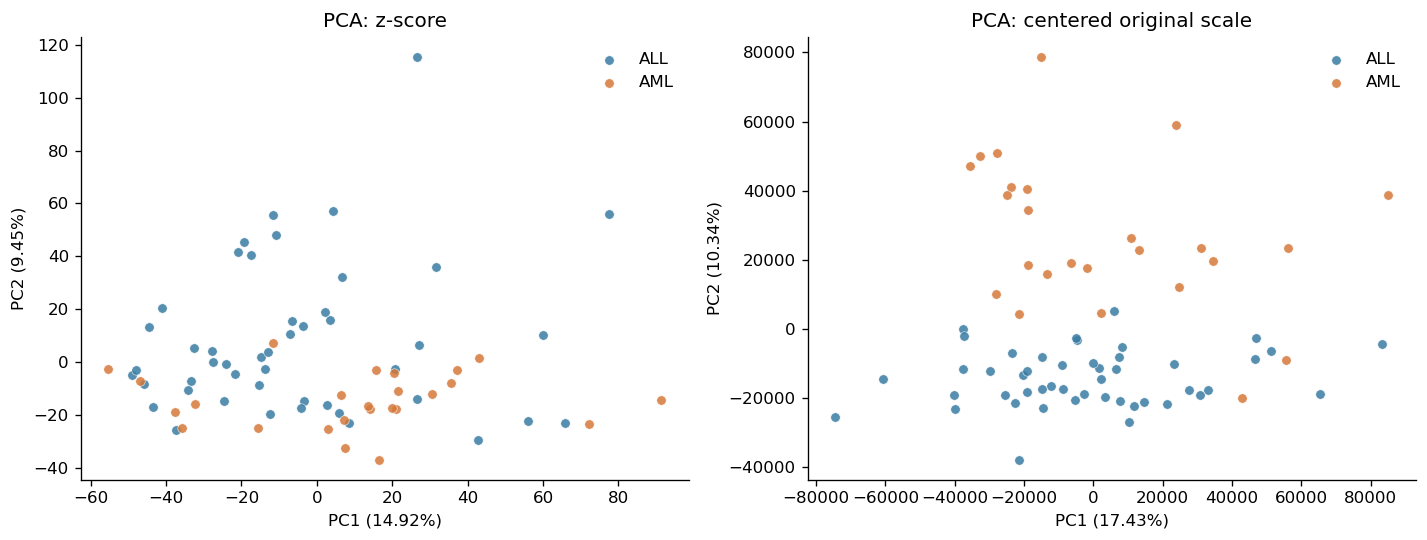

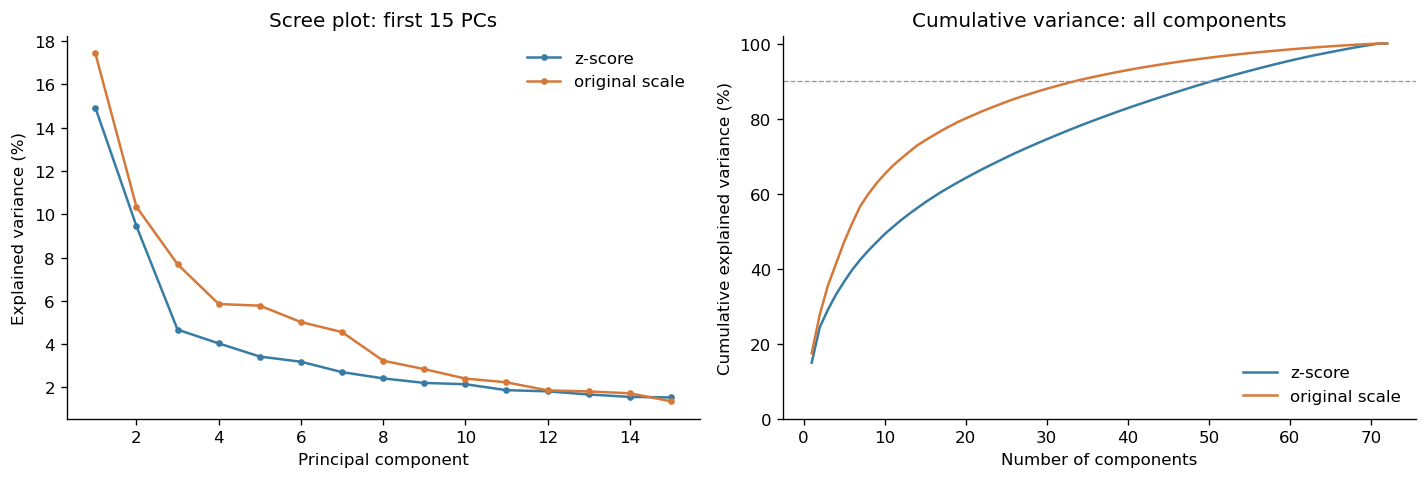

In [6]:
COLORS = {"ALL": "#387ca3", "AML": "#d57839"}

def draw_samples(ax, coordinates, title, xlabel, ylabel):
    for diagnosis, color in COLORS.items():
        mask = metadata.diagnosis.eq(diagnosis).to_numpy()
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1],
                   c=color, label=diagnosis, s=32, alpha=0.85, edgecolors="white", linewidths=0.35)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
draw_samples(axes[0], scores, "PCA: z-score",
             f"PC1 ({evr[0]:.2%})", f"PC2 ({evr[1]:.2%})")
draw_samples(axes[1], scores_raw, "PCA: centered original scale",
             f"PC1 ({evr_raw[0]:.2%})", f"PC2 ({evr_raw[1]:.2%})")
fig.tight_layout()
fig.savefig(RUN_DIR / "pca_scale_comparison.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
for name, ratios, cumulative, color in [
    ("z-score", evr, cum, "#387ca3"),
    ("original scale", evr_raw, cum_raw, "#d57839"),
]:
    axes[0].plot(np.arange(1, 16), ratios[:15] * 100, marker="o", ms=3, label=name, c=color)
    axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative * 100, label=name, c=color)
axes[0].set(xlabel="Principal component", ylabel="Explained variance (%)", title="Scree plot: first 15 PCs")
axes[1].set(xlabel="Number of components", ylabel="Cumulative explained variance (%)",
            title="Cumulative variance: all components", ylim=(0, 102))
axes[1].axhline(90, color="0.6", ls="--", lw=0.8)
for ax in axes:
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RUN_DIR / "pca_cumulative_variance.png", bbox_inches="tight")
plt.show()

In [7]:
pca_interpretation = f'''标准化后 PC1、PC2 分别解释 {evr[0]:.4%}、{evr[1]:.4%}，
合计 {evr[:2].sum():.4%}；达到 90% 累计解释率需要 {dimensions_for(evr, 0.9)} 个主成分，
因此前两轴只代表部分变异。原尺度前两轴合计为 {evr_raw[:2].sum():.4%}，
两种尺度的 PC1 top-5 探针重叠 {top_overlap}/5。
例如探针 **{top_ids[0]}** 的方向权重为 **{weights.loc[top_ids[0]]:+.6f}**：
其标准化值每增加 1，在其他标准化值固定时，PC1 得分改变该系数所对应的数值，
但这个代数贡献不等于干预效应。

本课 loading 定义为 components_.T，PC1 得分为中心化后的标准化特征与方向权重的内积。
PC1 最大化当前输入投影后的样本方差，不使用诊断标签，既不是某一个基因，也不保证是最能区分 ALL/AML 的方向。
同时翻转方向与得分的符号只改变轴朝向，解释率和样本关系不变。
中心化会使 72 行之间出现一个线性约束，矩阵秩至多为 min(72−1, 7129)=71，
所以至多有 71 个非零主成分。

图中标准化 PC1–PC2 的 ALL/AML 存在明显重叠；原尺度图的两类分布随尺度处理改变。\n原尺度强调原始绝对变异，标准化使各探针按相对变异参与；两种输入总方差不同，
不能用谁的解释率更高判断谁更正确。标准化可能放大低变异噪声；
这里将其作为按探针自身尺度计量的描述性选择，并保留原尺度对照。'''
display(Markdown(pca_interpretation))

标准化后 PC1、PC2 分别解释 14.9216%、9.4462%，
合计 24.3678%；达到 90% 累计解释率需要 51 个主成分，
因此前两轴只代表部分变异。原尺度前两轴合计为 27.7664%，
两种尺度的 PC1 top-5 探针重叠 0/5。
例如探针 **X92518_s_at** 的方向权重为 **+0.028786**：
其标准化值每增加 1，在其他标准化值固定时，PC1 得分改变该系数所对应的数值，
但这个代数贡献不等于干预效应。

本课 loading 定义为 components_.T，PC1 得分为中心化后的标准化特征与方向权重的内积。
PC1 最大化当前输入投影后的样本方差，不使用诊断标签，既不是某一个基因，也不保证是最能区分 ALL/AML 的方向。
同时翻转方向与得分的符号只改变轴朝向，解释率和样本关系不变。
中心化会使 72 行之间出现一个线性约束，矩阵秩至多为 min(72−1, 7129)=71，
所以至多有 71 个非零主成分。

图中标准化 PC1–PC2 的 ALL/AML 存在明显重叠；原尺度图的两类分布随尺度处理改变。
原尺度强调原始绝对变异，标准化使各探针按相对变异参与；两种输入总方差不同，
不能用谁的解释率更高判断谁更正确。标准化可能放大低变异噪声；
这里将其作为按探针自身尺度计量的描述性选择，并保留原尺度对照。

## 任务 3：UMAP 单因素对照与局部关系
运行前预测：n_neighbors=5 更强调小尺度邻域，min_dist=0.5 会改变点的紧凑程度，
换种子会改变优化得到的布局；同一局部关系若在四种设置和原始标准化空间都能找到，证据更稳。

四组 UMAP 使用任务 2 的同一份完整标准化矩阵 Z，不先做 PCA、不筛选探针。
每次拟合只传入 Z；诊断标签仅在嵌入完成后着色。
基线与各组只相差一个指定因素，n_components=2、metric=euclidean、n_jobs=1 固定。

In [8]:
baseline = dict(n_components=2, n_neighbors=15, min_dist=0.1,
                metric="euclidean", random_state=42, n_jobs=1)
umap_settings = {
    "baseline": baseline.copy(),
    "neighbors_5": {**baseline, "n_neighbors": 5},
    "min_dist_0.5": {**baseline, "min_dist": 0.5},
    "seed_7": {**baseline, "random_state": 7},
}
embeddings = {}
for name, params in umap_settings.items():
    with threadpool_limits(limits=2):
        embeddings[name] = UMAP(**params).fit_transform(Z)
    print(name, params, "->", embeddings[name].shape)
umap_parameter_table = pd.DataFrame(umap_settings).T.rename_axis("setting").reset_index()
display(umap_parameter_table)
(RUN_DIR / "umap_parameters.json").write_text(
    json.dumps(umap_settings, indent=2), encoding="utf-8"
)

baseline {'n_components': 2, 'n_neighbors': 15, 'min_dist': 0.1, 'metric': 'euclidean', 'random_state': 42, 'n_jobs': 1} -> (72, 2)
neighbors_5 {'n_components': 2, 'n_neighbors': 5, 'min_dist': 0.1, 'metric': 'euclidean', 'random_state': 42, 'n_jobs': 1} -> (72, 2)
min_dist_0.5 {'n_components': 2, 'n_neighbors': 15, 'min_dist': 0.5, 'metric': 'euclidean', 'random_state': 42, 'n_jobs': 1} -> (72, 2)
seed_7 {'n_components': 2, 'n_neighbors': 15, 'min_dist': 0.1, 'metric': 'euclidean', 'random_state': 7, 'n_jobs': 1} -> (72, 2)


,setting,n_components,n_neighbors,min_dist,metric,random_state,n_jobs
0,baseline,2,15,0.1,euclidean,42,1
1,neighbors_5,2,5,0.1,euclidean,42,1
2,min_dist_0.5,2,15,0.5,euclidean,42,1
3,seed_7,2,15,0.1,euclidean,7,1


625

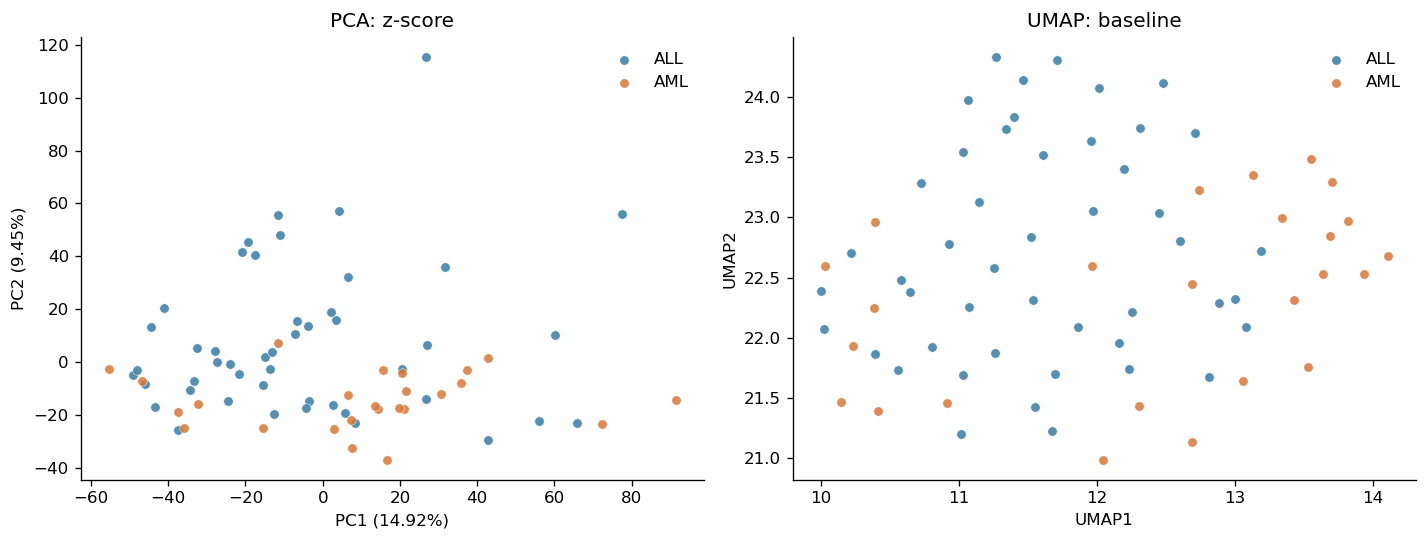

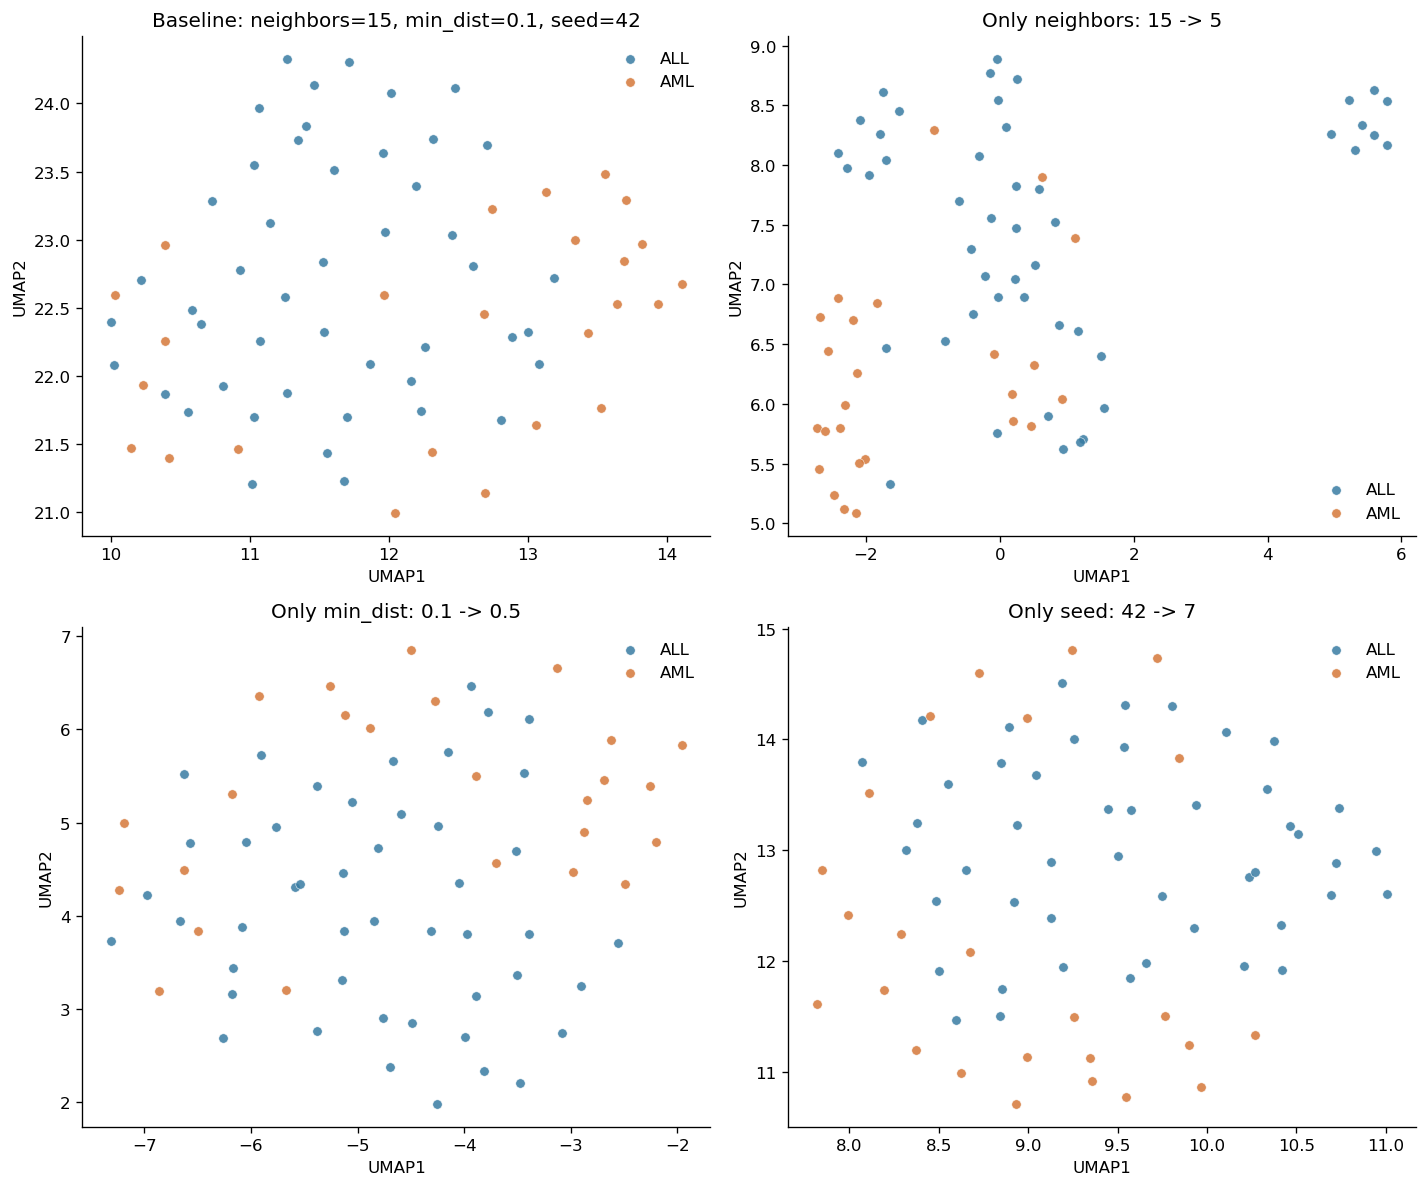

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
draw_samples(axes[0], scores, "PCA: z-score",
             f"PC1 ({evr[0]:.2%})", f"PC2 ({evr[1]:.2%})")
draw_samples(axes[1], embeddings["baseline"], "UMAP: baseline", "UMAP1", "UMAP2")
fig.tight_layout()
fig.savefig(RUN_DIR / "pca_vs_umap.png", bbox_inches="tight")
plt.show()

titles = {
    "baseline": "Baseline: neighbors=15, min_dist=0.1, seed=42",
    "neighbors_5": "Only neighbors: 15 -> 5",
    "min_dist_0.5": "Only min_dist: 0.1 -> 0.5",
    "seed_7": "Only seed: 42 -> 7",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, coordinates) in zip(axes.flat, embeddings.items()):
    draw_samples(ax, coordinates, titles[name], "UMAP1", "UMAP2")
fig.tight_layout()
fig.savefig(RUN_DIR / "umap_single_factor_comparison.png", bbox_inches="tight")
plt.show()

### 用样本编号核对邻域，不直接比较旋转/平移后的坐标
这里固定 **k=5** 做描述性核对，与 UMAP 的 n_neighbors 参数分开：
对每个样本求不含自身的 5 近邻，计算“与基线嵌入共有的邻居数 / 5”，
再对 72 个样本取均值；另计算与原始 Z 空间共有的邻居比例。
该数值是局部关系保留程度，不是分类准确率，也不用于挑选最好看的参数。

同时列出四组二维嵌入中始终互为 5 近邻、并在 Z 中也互为 5 近邻的具体样本对。
先按无标签的邻域关系确定样本对，再查看编号和诊断，不用标签定义稳定性。

In [10]:
K = 5
def neighbor_sets(matrix, k=K):
    with threadpool_limits(limits=2):
        indices = NearestNeighbors(n_neighbors=k + 1, metric="euclidean").fit(matrix).kneighbors(matrix, return_distance=False)
    return [set(int(j) for j in row if j != i) for i, row in enumerate(indices)]

def mean_overlap(left, right):
    return float(np.mean([len(a & b) / K for a, b in zip(left, right)]))

original_neighbors = neighbor_sets(Z)
pca_neighbors = neighbor_sets(scores[:, :2])
embedding_neighbors = {name: neighbor_sets(coordinates) for name, coordinates in embeddings.items()}
baseline_neighbors = embedding_neighbors["baseline"]
neighbor_rows = []
for name, sets in embedding_neighbors.items():
    per_sample = np.array([len(a & b) / K for a, b in zip(sets, baseline_neighbors)])
    neighbor_rows.append({
        "setting": name,
        "5NN overlap vs baseline (%)": per_sample.mean() * 100,
        "5NN overlap vs input Z (%)": mean_overlap(sets, original_neighbors) * 100,
        "minimum shared neighbors vs baseline": int(np.rint(per_sample.min() * K)),
        "maximum shared neighbors vs baseline": int(np.rint(per_sample.max() * K)),
    })
neighbor_summary = pd.DataFrame(neighbor_rows)
display(neighbor_summary)
print("PCA 2D 5NN overlap with Z:", f"{mean_overlap(pca_neighbors, original_neighbors):.2%}")
neighbor_summary.to_csv(RUN_DIR / "umap_neighbor_summary.csv", index=False)

all_neighborhoods = [original_neighbors, *embedding_neighbors.values()]
stable_pairs = [
    (i, j)
    for i in range(len(metadata))
    for j in range(i + 1, len(metadata))
    if all(j in neighborhood[i] and i in neighborhood[j] for neighborhood in all_neighborhoods)
]
stable_pair_table = pd.DataFrame([
    {
        "sample_a": metadata.iloc[i].sample_id, "sample_b": metadata.iloc[j].sample_id,
        "diagnosis_a": metadata.iloc[i].diagnosis, "diagnosis_b": metadata.iloc[j].diagnosis,
    }
    for i, j in stable_pairs
], columns=["sample_a", "sample_b", "diagnosis_a", "diagnosis_b"])
display(stable_pair_table)
stable_pair_table.to_csv(RUN_DIR / "stable_mutual_5nn_pairs.csv", index=False)

# 共有邻域与每种设置下的邻域均保留完整编号，便于追踪单个样本。
neighbor_detail = metadata.copy()
for name, sets in {"input_Z": original_neighbors, "PCA_2D": pca_neighbors, **embedding_neighbors}.items():
    neighbor_detail[name + "_5nn"] = [
        ", ".join(metadata.iloc[sorted(neighbors)].sample_id) for neighbors in sets
    ]
neighbor_detail.to_csv(RUN_DIR / "sample_neighbors.csv", index=False)
display(neighbor_detail.head(10))

,setting,5NN overlap vs baseline (%),5NN overlap vs input Z (%),minimum shared neighbors vs baseline,maximum shared neighbors vs baseline
0,baseline,100.000000,28.055556,5,5
1,neighbors_5,31.111111,42.222222,0,4
2,min_dist_0.5,53.611111,27.222222,0,5
3,seed_7,49.722222,30.000000,0,5


PCA 2D 5NN overlap with Z: 31.39%


,sample_a,sample_b,diagnosis_a,diagnosis_b
0,G005,G013,ALL,ALL
1,G005,G069,ALL,ALL
2,G013,G069,ALL,ALL


,sample_id,original_split,diagnosis,input_Z_5nn,PCA_2D_5nn,baseline_5nn,neighbors_5_5nn,min_dist_0.5_5nn,seed_7_5nn
0,G001,train,ALL,"G004, G007, G016, G026, G072","G004, G028, G030, G053, G063","G002, G003, G016, G034, G038","G003, G006, G007, G027, G049","G003, G006, G016, G038, G072","G003, G004, G016, G017, G028"
1,G002,train,ALL,"G010, G011, G014, G067, G071","G011, G014, G016, G024, G072","G001, G009, G011, G016, G038","G009, G010, G011, G014, G023","G009, G011, G016, G028, G038","G009, G016, G017, G024, G038"
2,G003,train,ALL,"G001, G004, G006, G009, G011","G001, G008, G032, G053, G063","G001, G004, G008, G034, G038","G001, G004, G006, G007, G008","G001, G006, G028, G032, G038","G001, G004, G016, G028, G032"
3,G004,train,ALL,"G001, G006, G007, G016, G031","G001, G007, G028, G030, G038","G032, G033, G049, G053, G064","G001, G003, G006, G007, G008","G007, G008, G027, G050, G051","G001, G003, G006, G008, G032"
4,G005,train,ALL,"G013, G015, G024, G041, G069","G013, G015, G021, G068, G069","G013, G014, G015, G068, G069","G013, G015, G024, G068, G069","G013, G014, G067, G068, G069","G013, G014, G048, G068, G069"
5,G006,train,ALL,"G010, G011, G012, G023, G031","G022, G023, G039, G056, G062","G022, G023, G034, G040, G062","G001, G003, G007, G027, G049","G001, G023, G025, G038, G051","G004, G010, G022, G023, G051"
6,G007,train,ALL,"G001, G004, G006, G031, G051","G032, G034, G036, G037, G038","G008, G027, G049, G051, G064","G003, G004, G006, G008, G027","G004, G008, G049, G051, G064","G008, G027, G030, G032, G049"
7,G008,train,ALL,"G001, G004, G007, G032, G035","G027, G032, G033, G049, G063","G004, G007, G034, G049, G064","G001, G003, G004, G006, G007","G007, G027, G034, G049, G051","G004, G007, G027, G049, G051"
8,G009,train,ALL,"G002, G003, G010, G011, G014","G001, G002, G014, G024, G048","G002, G011, G017, G024, G072","G002, G010, G011, G014, G023","G002, G011, G014, G017, G024","G002, G011, G016, G017, G024"
9,G010,train,ALL,"G011, G019, G026, G055, G071","G018, G025, G026, G042, G054","G019, G022, G042, G062, G071","G002, G011, G014, G016, G023","G019, G025, G026, G042, G071","G006, G022, G023, G025, G071"


In [11]:
# 完整坐标对应表嵌入 notebook，同时将 CSV 放入课程规定的 .tmp。
coordinate_table = metadata.copy()
coordinate_table["PCA_z_PC1"] = scores[:, 0]
coordinate_table["PCA_z_PC2"] = scores[:, 1]
coordinate_table["PCA_original_PC1"] = scores_raw[:, 0]
coordinate_table["PCA_original_PC2"] = scores_raw[:, 1]
for name, coordinates in embeddings.items():
    coordinate_table[name + "_UMAP1"] = coordinates[:, 0]
    coordinate_table[name + "_UMAP2"] = coordinates[:, 1]
coordinate_table.to_csv(RUN_DIR / "sample_coordinates.csv", index=False)
with pd.option_context("display.max_rows", 100, "display.max_columns", None, "display.precision", 5):
    display(coordinate_table)

,sample_id,original_split,diagnosis,PCA_z_PC1,PCA_z_PC2,PCA_original_PC1,PCA_original_PC2,baseline_UMAP1,baseline_UMAP2,neighbors_5_UMAP1,neighbors_5_UMAP2,min_dist_0.5_UMAP1,min_dist_0.5_UMAP2,seed_7_UMAP1,seed_7_UMAP2
0,G001,train,ALL,27.10521,6.44849,-12371.34270,-16505.72182,12.45395,23.03211,-1.69769,8.03891,-4.04579,4.35074,9.65891,11.98557
1,G002,train,ALL,3.50742,15.84580,-37565.86605,57.60867,12.19644,23.39715,-0.03057,8.54788,-3.38821,3.80829,10.41769,11.92004
2,G003,train,ALL,60.00638,10.39231,-19116.36689,-18216.30375,12.60394,22.80372,-1.95144,7.91361,-3.51354,4.69341,9.57013,11.84988
3,G004,train,ALL,20.64039,-2.62337,-8712.90413,-17386.58009,13.19152,22.71981,-2.41767,8.10498,-3.43726,5.52820,9.19306,11.94374
4,G005,train,ALL,-21.01202,41.79416,-29690.89529,-12205.16971,11.34554,23.73310,5.21088,8.54422,-4.49070,2.84576,10.46697,13.22225
5,G006,train,ALL,-3.45971,-14.75717,6640.05892,-11470.55667,12.25849,22.21047,-1.79643,8.25728,-4.24085,4.95846,9.12815,12.39232
6,G007,train,ALL,26.61849,-13.92580,27527.17146,-17788.21567,13.08012,22.08850,-2.08636,8.37705,-3.39122,6.10943,8.84472,11.50753
7,G008,train,ALL,56.07062,-22.14302,1556.43985,-11374.04796,12.88457,22.28546,-2.28450,7.97705,-3.77713,6.18738,8.85073,11.74759
8,G009,train,ALL,31.62804,36.08682,-60754.87705,-14400.90460,12.31596,23.74041,-0.05058,8.89104,-2.90229,3.24578,10.41661,12.32334
9,G010,train,ALL,-13.72597,-2.72959,-20364.85835,-13403.90359,11.53531,22.31683,0.08785,8.32155,-5.13654,4.45955,9.12693,12.89033


### PCA 与 UMAP 比较

| 方面 | PCA | UMAP |
| --- | --- | --- |
| 映射 | 线性投影 | 非线性嵌入 |
| 主要保留/优化的信息 | 依次最大化投影方差，方向彼此正交 | 高维局部邻域图与低维嵌入的对应 |
| 坐标轴含义 | 探针的线性组合，方向权重可追踪 | 优化得到的嵌入坐标，无固定疾病含义 |
| 方差解释率 | 可以报告，分母是当前输入总方差 | 没有同等定义 |
| 局部邻域与全局距离 | 截断会损失距离和邻域信息 | 侧重局部，岛屿间距离/面积不能直接解释 |
| 参数与随机性 | 尺度和保留维数关键；本次 full SVD | 邻居数、min_dist、度量、种子均影响布局 |
| 预测时的拟合范围 | 每个训练折内拟合 scaler/PCA，再 transform 验证折 | 支持 transform 的实现也只能在训练折拟合，不能用全数据嵌入评分 |

三条判断：
1. 图和编号对应表能提出具体局部相似关系；参数对照能说明这些关系是否稳定。
2. 诊断着色能展示表达结构与标签在当前样本中的对应；分离不等于机制、真实亚型或预测成绩。
3. 二维图能呈现当前嵌入布局；本数据没有批次字段，不能据此宣称已排除批次影响。

## 任务 1 验证：只在原始训练集内比较两条 Pipeline
运行前预测：PCA(10) 可能去除噪声，也可能丢失弱分类信号，优劣须由同一组验证折比较。
固定 StratifiedKFold(3, shuffle=True, random_state=42)，
比较 StandardScaler → 1近邻 与 StandardScaler → PCA(10, full) → 1近邻。
读取全部标签用于描述性着色并不构成新测试；这里评分只取原始 38 个 train 样本的标签，
不计算原始 34 个 test 样本的新测试成绩、不按结果调参。

In [13]:
train_mask = metadata.original_split.eq("train").to_numpy()
X_train = X_array[train_mask]
y_train = metadata.loc[train_mask, "diagnosis"].to_numpy()
assert X_train.shape == (38, 7129)
assert pd.Series(y_train).value_counts().to_dict() == {"ALL": 27, "AML": 11}
cv_splits = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=42).split(X_train, y_train))
pipelines = {
    "Scaler -> 1NN": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=1)),
    ]),
    "Scaler -> PCA(10) -> 1NN": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=10, svd_solver="full")),
        ("knn", KNeighborsClassifier(n_neighbors=1)),
    ]),
}
cv_rows = []
cv_sample_rows = []
for fold, (fit_indices, validation_indices) in enumerate(cv_splits, 1):
    for role, indices in [("fit", fit_indices), ("validation", validation_indices)]:
        for index in indices:
            cv_sample_rows.append({
                "fold": fold, "role": role,
                "sample_id": metadata.loc[train_mask].iloc[index].sample_id,
            })
for name, model in pipelines.items():
    with threadpool_limits(limits=2):
        result = cross_validate(
            model, X_train, y_train, cv=cv_splits, scoring="balanced_accuracy", n_jobs=1
        )
    cv_rows.append({
        "pipeline": name,
        **{f"fold {i + 1} BA": float(score) for i, score in enumerate(result["test_score"])},
        "mean BA": float(result["test_score"].mean()),
    })
cv_table = pd.DataFrame(cv_rows)
display(cv_table)
cv_table.to_csv(RUN_DIR / "training_only_cv.csv", index=False)
pd.DataFrame(cv_sample_rows).to_csv(RUN_DIR / "cv_sample_membership.csv", index=False)
cv_difference = float(cv_table.iloc[1]["mean BA"] - cv_table.iloc[0]["mean BA"])
cv_interpretation = (
    f"三折平均 BA：不加 PCA 为 {cv_table.iloc[0]['mean BA']:.6f}，"
    f"加入 PCA(10) 为 {cv_table.iloc[1]['mean BA']:.6f}，差值为 {cv_difference:+.6f}。"
    f"加入 PCA 后本次平均 BA 降低 {-cv_difference * 100:.4f} 个百分点，"
    "说明固定 10 维压缩并未改善这次验证；这不能证明差异的生物学原因。"
    "这描述同一小样本训练集上的固定流程对照，三折不是独立研究；"
    "不把均值差异解释为统计显著性、临床泛化或因果效应。"
)
display(Markdown(cv_interpretation))

,pipeline,fold 1 BA,fold 2 BA,fold 3 BA,mean BA
0,Scaler -> 1NN,0.819444,0.875000,0.833333,0.842593
1,Scaler -> PCA(10) -> 1NN,0.694444,0.763889,0.833333,0.763889


三折平均 BA：不加 PCA 为 0.842593，加入 PCA(10) 为 0.763889，差值为 -0.078704。加入 PCA 后本次平均 BA 降低 7.8704 个百分点，说明固定 10 维压缩并未改善这次验证；这不能证明差异的生物学原因。这描述同一小样本训练集上的固定流程对照，三折不是独立研究；不把均值差异解释为统计显著性、临床泛化或因果效应。

## 任务 4：退出卡与三道作业
下面文字由本次实际输出的数值、权重和近邻对照填入，同时写入学生工作单和 README。

In [14]:
claim = "当前 PCA/UMAP 支持对白血病表达谱做结构探索，尚不能接受仅凭二维分离就证明疾病机制并能预测新患者的主张。"
evidence = (
    f"标准化 PCA 前两轴解释率为 {evr[0]:.4%} 和 {evr[1]:.4%}，"
    f"合计 {evr[:2].sum():.4%}；仅把 UMAP 邻居数由 15 改为 5 后，"
    f"二维 5 近邻与基线的平均共有比例为 {variant_overlap['neighbors_5']:.2f}%。"
)
reasoning = "PCA 保留的是投影方差，UMAP 表示的是经过参数化优化的局部邻域，而诊断只是事后着色，因此图形模式不能直接给出因果解释或未见患者的预测误差。"
boundary = (
    "本数据缺少批次和患者重复映射，且历史测试结果曾在 HW03 查看；"
    "下一步应核验患者独立性和批次信息、锁定训练流程后在独立队列验证预测表现，"
    "机制主张还需针对候选通路或分子的功能干预证据。"
)
exit_card = "\n".join(f"{i}. **{label}：**{text}" for i, (label, text) in enumerate(
    [("主张", claim), ("证据", evidence), ("推理", reasoning), ("边界", boundary)], 1
))
homework = f'''
1. **PC1 代表什么？**它是让当前标准化表达矩阵投影方差最大的单位线性方向，解释总方差的
   {evr[0]:.4%}；例如 {top_ids[0]} 的权重为 {weights.loc[top_ids[0]]:+.6f}，
   表示该探针标准化表达在 PC1 中的带符号系数，而不是一个致病效应。
2. **为什么考虑标准化？**各探针原始标准差从 {probe_sd.min():.3f} 到 {probe_sd.max():.3f}，
   原尺度前两轴解释 {evr_raw[:2].sum():.4%}，标准化后为 {evr[:2].sum():.4%}，
   两套 PC1 top-5 名单重叠 {top_overlap}/5；z-score 使原始幅度较小的探针也按自身尺度参与，
   代价是可能放大低变异噪声，因此不能以解释率较高判定某种尺度普遍更好。
3. **UMAP 能说明什么？**它能提出样本局部相似关系，例如跨设置并在原始 Z 中稳定的样本对
   {pair_examples}；只改种子后的平均 5 近邻共有比例为 {variant_overlap["seed_7"]:.2f}%，
   说明一次嵌入的细节并不固定，不能把岛屿、岛屿间距离或诊断分离当作真实亚型、机制或泛化表现。
'''
display(Markdown(exit_card))
display(Markdown(homework))
limitations = (
    "72 份样本来自同一历史数据；教学编号不能核验患者独立性，缺少批次字段，"
    "无法检验或排除批次效应；7,129 个探针包含控制探针，不等于不同基因数。"
    "全数据图形只用于描述；三折训练内验证不能替代新的独立队列，"
    "历史 34 份测试样本也不能重新当作完全未见的确认性证据。"
)
display(Markdown("### 结论边界\n" + limitations))

1. **主张：**当前 PCA/UMAP 支持对白血病表达谱做结构探索，尚不能接受仅凭二维分离就证明疾病机制并能预测新患者的主张。
2. **证据：**标准化 PCA 前两轴解释率为 14.9216% 和 9.4462%，合计 24.3678%；仅把 UMAP 邻居数由 15 改为 5 后，二维 5 近邻与基线的平均共有比例为 31.11%。
3. **推理：**PCA 保留的是投影方差，UMAP 表示的是经过参数化优化的局部邻域，而诊断只是事后着色，因此图形模式不能直接给出因果解释或未见患者的预测误差。
4. **边界：**本数据缺少批次和患者重复映射，且历史测试结果曾在 HW03 查看；下一步应核验患者独立性和批次信息、锁定训练流程后在独立队列验证预测表现，机制主张还需针对候选通路或分子的功能干预证据。


1. **PC1 代表什么？**它是让当前标准化表达矩阵投影方差最大的单位线性方向，解释总方差的
   14.9216%；例如 X92518_s_at 的权重为 +0.028786，
   表示该探针标准化表达在 PC1 中的带符号系数，而不是一个致病效应。
2. **为什么考虑标准化？**各探针原始标准差从 26.517 到 15782.799，
   原尺度前两轴解释 27.7664%，标准化后为 24.3678%，
   两套 PC1 top-5 名单重叠 0/5；z-score 使原始幅度较小的探针也按自身尺度参与，
   代价是可能放大低变异噪声，因此不能以解释率较高判定某种尺度普遍更好。
3. **UMAP 能说明什么？**它能提出样本局部相似关系，例如跨设置并在原始 Z 中稳定的样本对
   G005–G013、G005–G069、G013–G069；只改种子后的平均 5 近邻共有比例为 49.72%，
   说明一次嵌入的细节并不固定，不能把岛屿、岛屿间距离或诊断分离当作真实亚型、机制或泛化表现。


### 结论边界
72 份样本来自同一历史数据；教学编号不能核验患者独立性，缺少批次字段，无法检验或排除批次效应；7,129 个探针包含控制探针，不等于不同基因数。全数据图形只用于描述；三折训练内验证不能替代新的独立队列，历史 34 份测试样本也不能重新当作完全未见的确认性证据。